## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import setup

Total combinations of features: 1023


## Setup

In [4]:
VERSION = 3
RANDOM_SEED = 1

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/classification/_<VAR_X>/cut_*/*'
METRIC = 'test_auc'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(12, 29)

In [6]:
df_results.columns

Index(['strategy_id', 'features_id', 'y', 'features', 'nfeatures',
       'cat_features', 'best_params', 'best_score', 'best_iteration',
       'test_size', 'random_state', 'loss_function', 'eval_metric',
       'train_eval', 'test_accuracy', 'test_f1', 'test_precision',
       'test_recall', 'test_auc', 'all_accuracy', 'all_f1', 'all_precision',
       'all_recall', 'all_auc', 'f_name', 'labels', 'y_test', 'y_pred',
       'y_pred_proba'],
      dtype='object')

In [7]:
cols = ['y','features_id','strategy_id','train_eval','test_accuracy','all_accuracy','test_f1','test_precision','test_recall','test_auc','all_auc','f_name']
df_results[cols].sort_values(METRIC, ascending=False)

,y,features_id,strategy_id,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name
8,gender_median,0,4,0.669259,0.757576,0.698795,0.739412,0.750916,0.744949,0.929878,0.860572,median_0_4
6,gender_mean,0,2,0.663428,0.750000,0.698795,0.702857,0.750000,0.736364,0.898557,0.866131,mean_0_2
1,gender_mean,1,1,0.688265,0.593750,0.674699,0.593843,0.635985,0.579254,0.810748,0.826961,mean_1_1
0,gender_mean,0,1,0.480184,0.593750,0.686747,0.547009,0.568376,0.565851,0.809261,0.873057,mean_0_1
9,gender_median,1,4,0.581989,0.606061,0.716867,0.605706,0.713450,0.618182,0.797311,0.882212,median_1_4
7,gender_mean,1,2,0.521272,0.625000,0.674699,0.619600,0.623737,0.621212,0.786472,0.859313,mean_1_2
5,gender_mean,1,3,0.398302,0.545455,0.728916,0.518833,0.540476,0.507353,0.779926,0.880994,mean_1_3
11,gender_mode,1,5,0.626957,0.606061,0.650602,0.517677,0.748485,0.527778,0.764593,0.844393,mode_1_5
10,gender_mode,0,5,0.648174,0.666667,0.698795,0.567273,0.564103,0.583333,0.763455,0.826665,mode_0_5
4,gender_mean,0,3,0.471547,0.515152,0.692771,0.500661,0.522661,0.487745,0.753578,0.857215,mean_0_3


In [8]:
best_id = df_results[METRIC].idxmax()
best_id

8

In [9]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_f1','test_auc']]

,y,features,train_eval,test_f1,test_auc
8,gender_median,[ngender_r],0.669259,0.739412,0.929878


In [10]:
df_results.loc[best_id].features

['ngender_r']

In [11]:
df_results.loc[best_id]

strategy_id                                                       4
features_id                                                       0
y                                                     gender_median
features                                                [ngender_r]
nfeatures                                                         1
cat_features                                                     []
best_params       {'depth': 2, 'learning_rate': 0.03, 'l2_leaf_r...
best_score        {'learn': {'MultiClass': 0.669259232970109}, '...
best_iteration                                                  199
test_size                                                       0.2
random_state                                                      1
loss_function                                            MultiClass
eval_metric                                              MultiClass
train_eval                                                 0.669259
test_accuracy                                   

In [12]:
df_results.loc[best_id].strategy_id, setup.STRATEGY[df_results.loc[best_id].strategy_id]

(4, {'cuts': [0.3, 0.7], 'gt_agg': 'median'})

In [13]:
metric = df_results.loc[best_id].y.replace('gender_','')
cut_id = df_results.loc[best_id].strategy_id
gt_agg = setup.STRATEGY[df_results.loc[best_id].strategy_id]['gt_agg']

f_name = DIR.replace('<VAR_X>', metric).replace('cut_*/*', f"cut_{cut_id}")
f_name = f"{f_name}/{metric}_{df_results.loc[best_id].features_id}_{df_results.loc[best_id].strategy_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs1/classification/_median/cut_4/median_0_4'

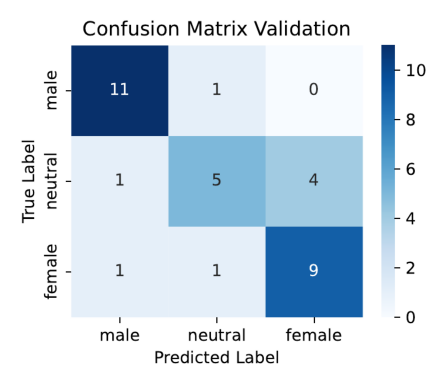

In [14]:
# predictions
fn = f"{f_name}_confusion_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



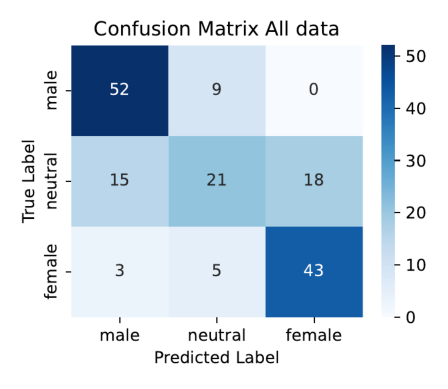

In [15]:
# predictions
fn = f"{f_name}_confusion_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



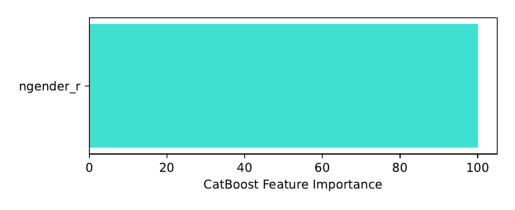

In [16]:
# predictors
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

